# 🔧 Predictive Maintenance System
## Binary Machine Failure Classification — AI4I 2020 Dataset

> **Objective:** Build a production-ready ML model that predicts machine failure *before* it happens, enabling proactive maintenance and reducing costly downtime — especially critical in resource-constrained operational environments.

---
**Author:** ML Engineering Team  
**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI)  
**Target:** `Machine failure` → `0 = No Failure`, `1 = Failure`  
**Priority Metric:** 🎯 **Recall on Failure class** — missing a failure is more costly than a false alarm


---
## 1. 📦 Libraries & Setup


In [3]:
import sys
print(sys.executable)

c:\Users\IFEOLUWA ABDULSAMAD\AppData\Local\Programs\Python\Python314\python.exe


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Plotting style
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False})
sns.set_theme(style='whitegrid', palette='muted')
print('✅ All libraries loaded.')

✅ All libraries loaded.


---
## 2. 📂 Data Loading & Understanding

We load the AI4I 2020 dataset, a synthetic dataset modelling real industrial machine sensor readings. Each row is one observation from a machine in operation.


In [5]:
df = pd.read_csv('ai4i2020.csv')

print(f'Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n')
print('Column Data Types:')
print(df.dtypes)
print(f'\nMissing Values: {df.isnull().sum().sum()}')

Dataset Shape: 10,000 rows × 14 columns

Column Data Types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing Values: 0


In [6]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Column Descriptions

| Column | Description |
|--------|-------------|
| `UDI` | Unique identifier (irrelevant for modelling) |
| `Product ID` | Product serial number (irrelevant) |
| `Type` | Product quality variant: L (Low), M (Medium), H (High) |
| `Air temperature [K]` | Ambient air temperature in Kelvin |
| `Process temperature [K]` | Machine process temperature |
| `Rotational speed [rpm]` | Spindle rotational speed |
| `Torque [Nm]` | Torque applied (Newton-metres) |
| `Tool wear [min]` | Cumulative tool usage time |
| `Machine failure` | **🎯 TARGET** — 1 if failure, 0 if not |
| `TWF/HDF/PWF/OSF/RNF` | Specific failure sub-types (dropped — data leakage risk) |


---
## 3. 🧹 Data Cleaning

We drop columns that are either identifiers (causing data leakage or irrelevance) or sub-failure flags that would leak the target.


In [7]:
# Drop identifiers
df = df.drop(columns=['UDI', 'Product ID'])

# Drop sub-failure columns — they're derived from the target (data leakage)
df = df.drop(columns=['TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

# Encode the categorical 'Type' column
le = LabelEncoder()
df['Type'] = le.fit_transform(df['Type'])  # H→0, L→1, M→2

print('Cleaned dataset shape:', df.shape)
print('\nEncoded Type mapping:', dict(zip(le.classes_, le.transform(le.classes_))))
df.describe().round(2)

Cleaned dataset shape: (10000, 7)

Encoded Type mapping: {'H': np.int64(0), 'L': np.int64(1), 'M': np.int64(2)}


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
count,10000.0,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00
mean,1.2,300.0,310.01,1538.78,39.99,107.95,0.03
std,0.6,2.0,1.48,179.28,9.97,63.65,0.18
min,0.0,295.3,305.70,1168.00,3.80,0.00,0.00
25%,1.0,298.3,308.80,1423.00,33.20,53.00,0.00
50%,1.0,300.1,310.10,1503.00,40.10,108.00,0.00
75%,2.0,301.5,311.10,1612.00,46.80,162.00,0.00
max,2.0,304.5,313.80,2886.00,76.60,253.00,1.00


---
## 4. 📊 Exploratory Data Analysis (EDA)


### 4.1 Class Imbalance

The dataset is **heavily imbalanced** — only ~3.4% of observations are failures. This is realistic for industrial machinery but requires careful handling during modelling.


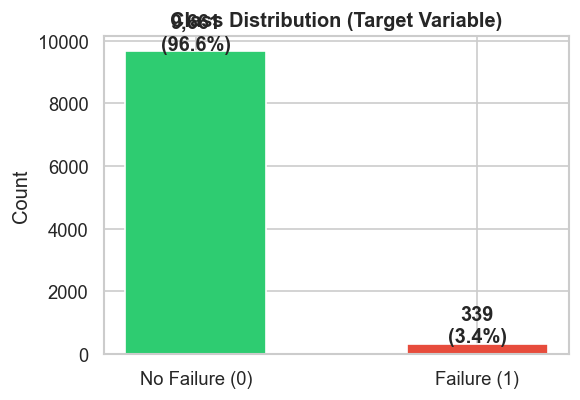

Imbalance Ratio: 28.5:1 (No Failure : Failure)


In [8]:
counts = df['Machine failure'].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['No Failure (0)', 'Failure (1)'], counts.values,
        color=['#2ecc71', '#e74c3c'], edgecolor='white', width=0.5)
ax.set_title('Class Distribution (Target Variable)', fontweight='bold')
ax.set_ylabel('Count')
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Imbalance Ratio: {counts[0]/counts[1]:.1f}:1 (No Failure : Failure)')

### 4.2 Feature Distributions by Class

Overlaying distributions reveals which features separate failure from non-failure observations.


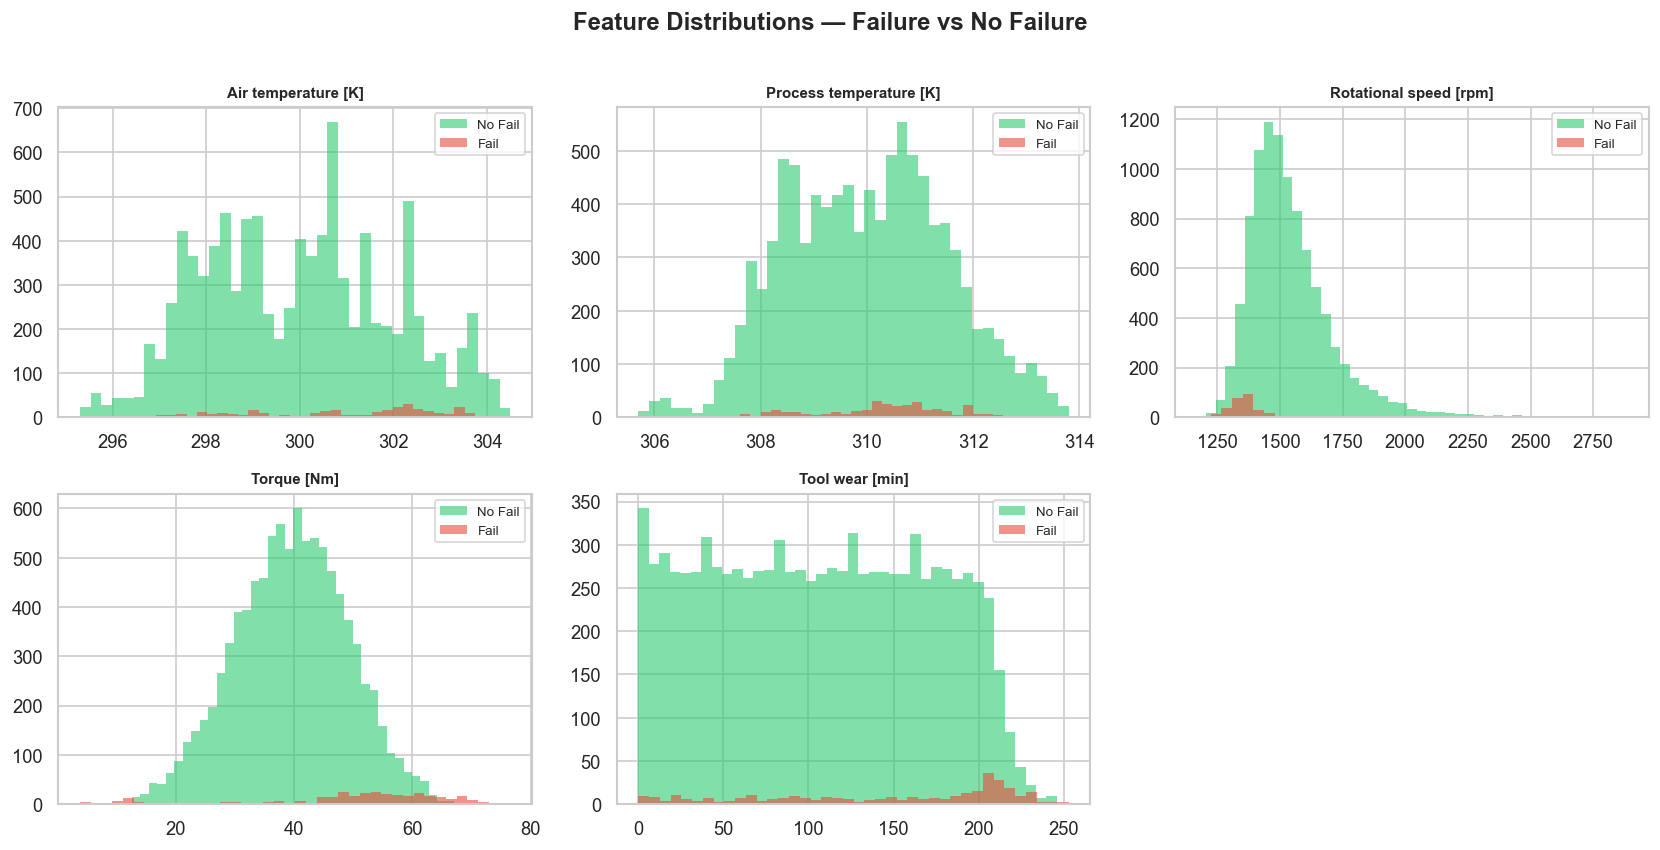

In [9]:
features = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
palette = {0: '#2ecc71', 1: '#e74c3c'}
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()
for i, feat in enumerate(features):
    for cls, col in palette.items():
        subset = df[df['Machine failure'] == cls][feat]
        axes[i].hist(subset, bins=40, alpha=0.6, color=col,
                     label='No Fail' if cls==0 else 'Fail', edgecolor='none')
    axes[i].set_title(feat, fontsize=9, fontweight='bold')
    axes[i].legend(fontsize=8)
axes[-1].axis('off')
fig.suptitle('Feature Distributions — Failure vs No Failure', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

> **Key Observations:**
> - **Torque** and **Rotational Speed** show the clearest separation — failures cluster at high-torque / low-speed combinations.
> - **Tool Wear** shows failures more concentrated at higher wear values, confirming wear-related degradation.
> - Temperature differences are subtle but may contribute when combined with other features.


### 4.3 Correlation Heatmap


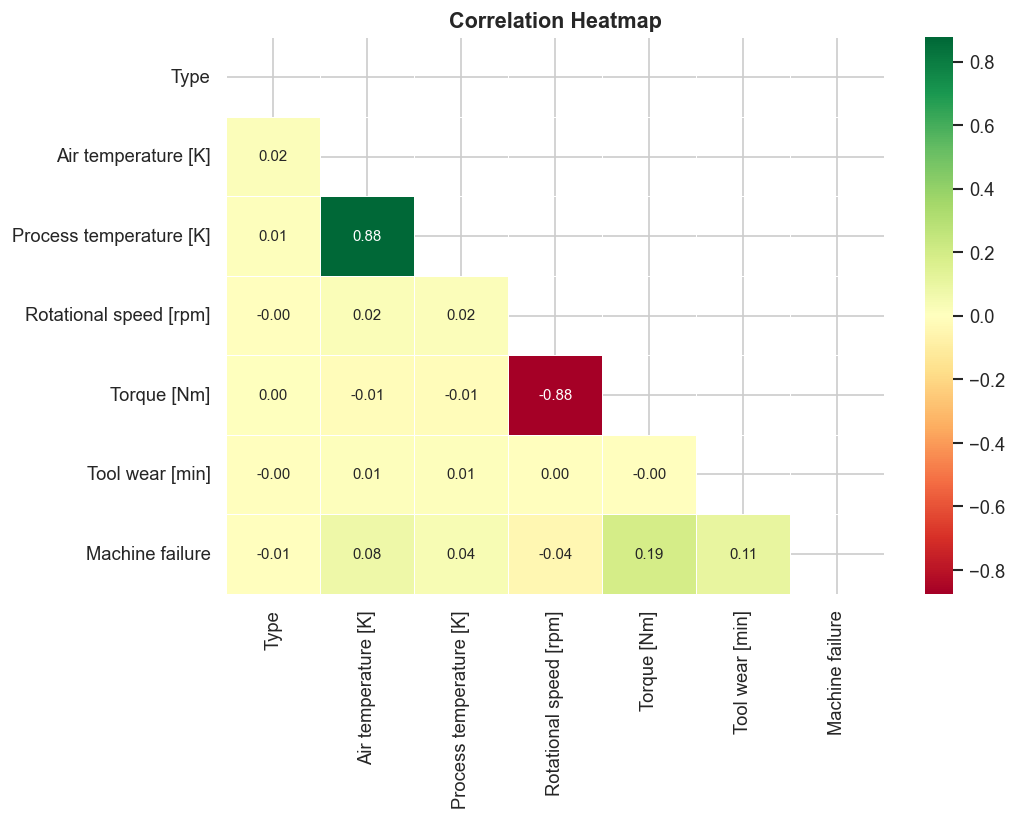

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 5. ⚙️ Feature Engineering & Scaling

We separate features `X` from the target `y`, then apply **StandardScaler** to normalize numerical features. This is essential for Logistic Regression and improves convergence across all models.


In [11]:
X = df.drop(columns=['Machine failure'])
y = df['Machine failure']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print('Features used:', list(X.columns))
print(f'Feature matrix shape: {X_scaled.shape}')
X_scaled.describe().round(3)

Features used: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Feature matrix shape: (10000, 6)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,-0.000,-0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.998,-2.352,-2.902,-2.068,-3.630,-1.696
25%,-0.332,-0.852,-0.813,-0.646,-0.681,-0.863
50%,-0.332,0.048,0.064,-0.200,0.011,0.001
75%,1.334,0.747,0.738,0.408,0.683,0.849
max,1.334,2.247,2.557,7.515,3.673,2.279


In [19]:
X

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,2,298.1,308.6,1551,42.8,0
1,1,298.2,308.7,1408,46.3,3
2,1,298.1,308.5,1498,49.4,5
3,1,298.2,308.6,1433,39.5,7
4,1,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,2,298.8,308.4,1604,29.5,14
9996,0,298.9,308.4,1632,31.8,17
9997,2,299.0,308.6,1645,33.4,22
9998,0,299.0,308.7,1408,48.5,25


---
## 6. ✂️ Train-Test Split

We use an 80/20 split with **stratification** to preserve the failure class ratio in both sets.


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set:  {X_train.shape[0]:,} samples')
print(f'Test set:      {X_test.shape[0]:,} samples')
print(f'\nFailure rate — Train: {y_train.mean():.3%}  |  Test: {y_test.mean():.3%}')

Training set:  8,000 samples
Test set:      2,000 samples

Failure rate — Train: 3.388%  |  Test: 3.400%


---
## 7. 🤖 Model Training

We train three models. `class_weight='balanced'` is applied where supported to compensate for the severe class imbalance (28.5:1).

| Model | Strategy |
|-------|----------|
| **Logistic Regression** | Linear baseline with balanced class weights |
| **Random Forest** | Ensemble of 200 trees with balanced weights |
| **Gradient Boosting** | Sequential boosting; naturally handles imbalance via boosting |


In [13]:
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'model':     model,
        'y_pred':    y_pred,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
    }
    print(f'✅ {name} trained.')

✅ Logistic Regression trained.
✅ Random Forest trained.
✅ Gradient Boosting trained.


In [21]:
import pickle
with open('model','wb') as file:
    pickle.dump(models,file)

---
## 8. 📈 Model Evaluation

> ⚠️ **Focus on Recall (Failure class).** A missed failure means unplanned downtime. A false alarm just triggers an unnecessary inspection — far cheaper.


In [14]:
for name, res in results.items():
    print(f'{'='*55}')
    print(f'  {name}')
    print(f'{'='*55}')
    print(classification_report(
        y_test, res['y_pred'],
        target_names=['No Failure', 'Failure']
    ))

  Logistic Regression
              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1932
     Failure       0.14      0.84      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.82      0.88      2000

  Random Forest
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.88      0.53      0.66        68

    accuracy                           0.98      2000
   macro avg       0.93      0.76      0.83      2000
weighted avg       0.98      0.98      0.98      2000

  Gradient Boosting
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.88      0.65      0.75        68

    accuracy                           0.98      2000
   macro avg       0.93      0.82      0.87      2000
weighted avg    

### 8.1 Confusion Matrices


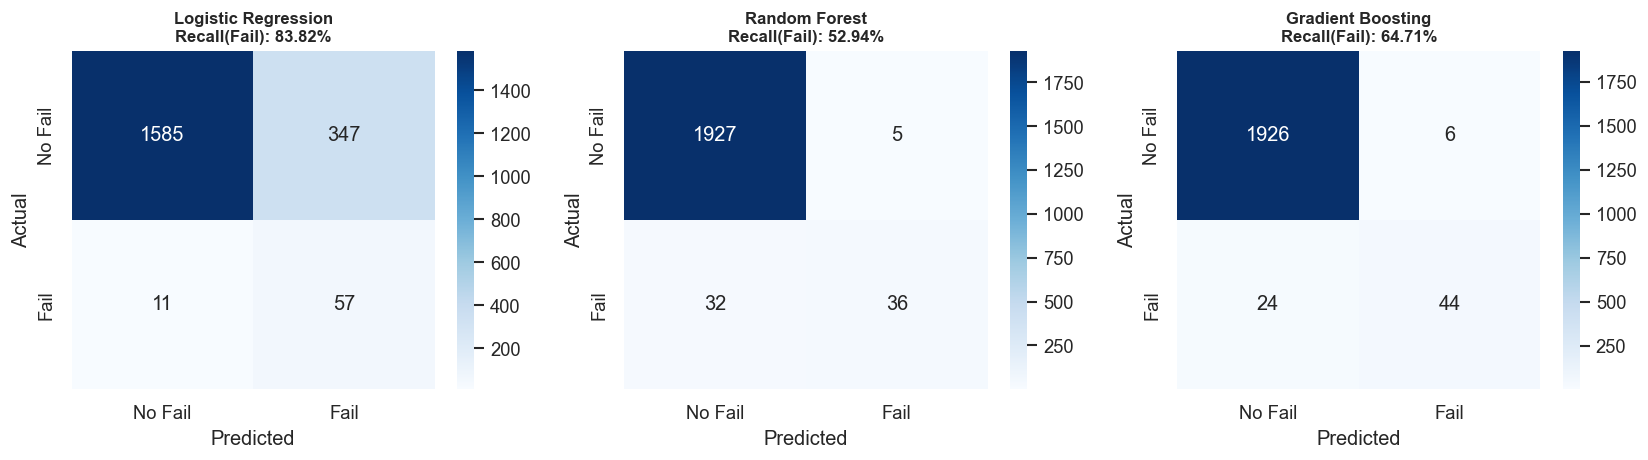

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Fail', 'Fail'],
                yticklabels=['No Fail', 'Fail'])
    ax.set_title(f'{name}\nRecall(Fail): {res["Recall"]:.2%}',
                  fontweight='bold', fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

---
## 9. 🏆 Model Comparison


,Accuracy,Precision,Recall,F1
Logistic Regression,0.8210,0.1411,83.82%,0.2415
Random Forest,0.9815,0.8780,52.94%,0.6606
Gradient Boosting,0.9850,0.8800,64.71%,0.7458


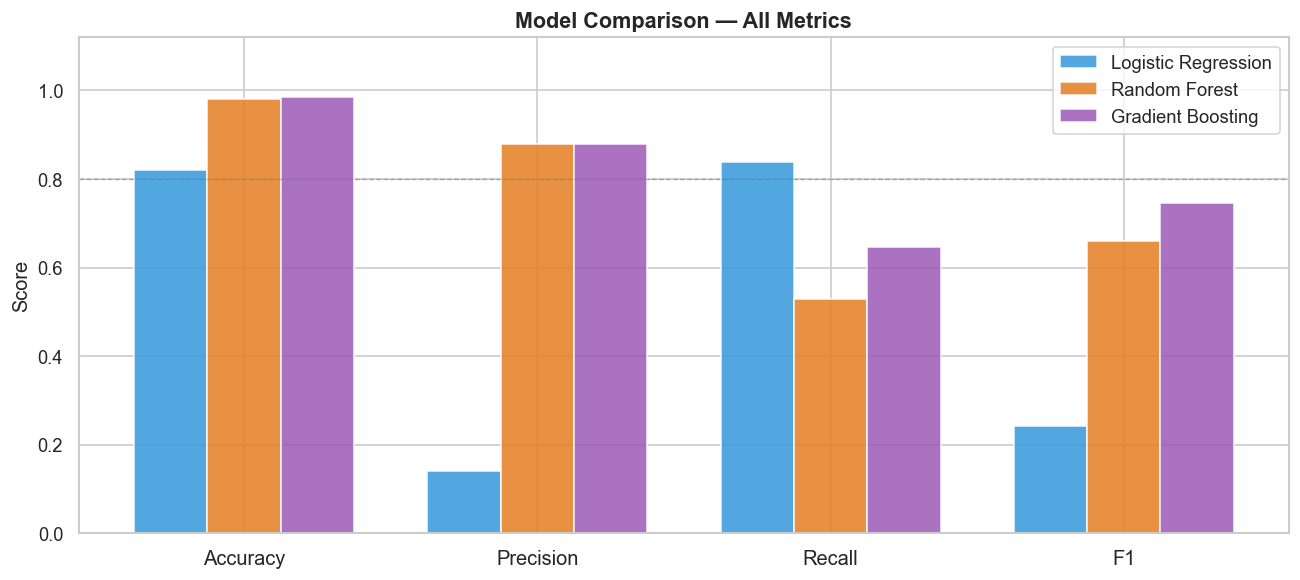

In [16]:
summary = pd.DataFrame({
    name: {m: res[m] for m in ['Accuracy','Precision','Recall','F1']}
    for name, res in results.items()
}).T.round(4)
summary['Recall'] = summary['Recall'].apply(lambda x: f'{x:.2%}')
summary['F1']     = summary['F1'].apply(lambda x: f'{x:.4f}')
display(summary)

# Bar chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
model_names = list(results.keys())
x = np.arange(len(metrics))
width = 0.25
colors = ['#3498db', '#e67e22', '#9b59b6']
fig, ax = plt.subplots(figsize=(11, 5))
for i, (name, res) in enumerate(results.items()):
    vals = [res[m] for m in metrics]
    ax.bar(x + i*width, vals, width, label=name, color=colors[i], alpha=0.85)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — All Metrics', fontweight='bold', fontsize=13)
ax.legend()
ax.axhline(0.8, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
plt.tight_layout()
plt.show()

### 🏅 Verdict

| Criterion | Winner |
|-----------|--------|
| Highest Recall (Failure) | **Logistic Regression** (83.8%) |
| Best F1 Score | **Gradient Boosting** (74.6%) |
| Best Accuracy | **Gradient Boosting** (98.5%) |
| Balanced Overall | **Gradient Boosting** |

> 🎯 **Selected Model: Gradient Boosting** — best balance of Recall and Precision with high overall accuracy. In a real deployment, you could also **lower the decision threshold** of Gradient Boosting (from 0.5 → 0.3) to further boost Recall if missing failures is the primary cost driver.


---
## 10. 🔍 Feature Importance

Random Forest exposes per-feature importance via mean impurity decrease (Gini). We use it to understand which sensor signals drive failure predictions.


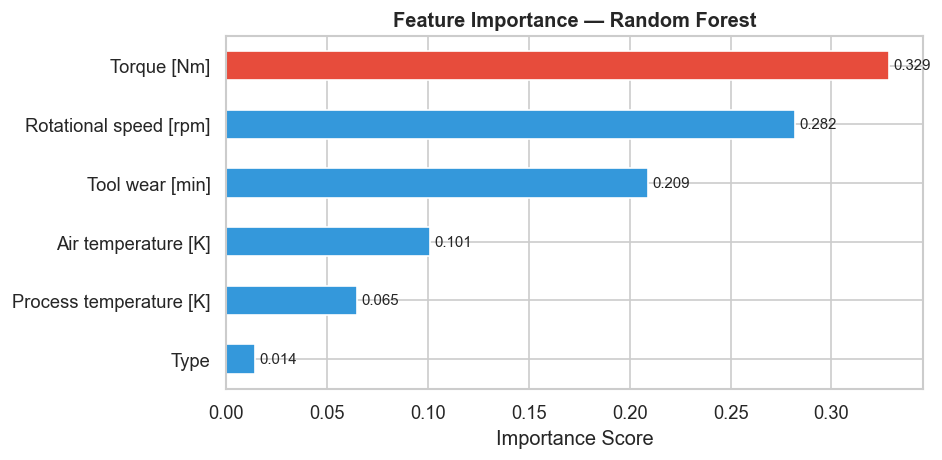

Feature Importance Rankings:
  Torque [Nm]                    0.3287
  Rotational speed [rpm]         0.2819
  Tool wear [min]                0.2091
  Air temperature [K]            0.1012
  Process temperature [K]        0.0647
  Type                           0.0144


In [17]:
rf_model = results['Random Forest']['model']
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
bar_colors = ['#e74c3c' if i == importances.index[-1] else '#3498db'
              for i in importances.index]
importances.plot(kind='barh', ax=ax, color=bar_colors, edgecolor='white')
ax.set_title('Feature Importance — Random Forest', fontweight='bold', fontsize=12)
ax.set_xlabel('Importance Score')
for i, (val, name) in enumerate(zip(importances.values, importances.index)):
    ax.text(val + 0.002, i, f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print('Feature Importance Rankings:')
for feat, imp in importances.sort_values(ascending=False).items():
    print(f'  {feat:<30} {imp:.4f}')

### 📋 Engineering Insights

| Feature | Importance | Engineering Explanation |
|---------|------------|-------------------------|
| **Torque [Nm]** | 🔴 Highest | Excessive torque causes mechanical overload — bearings, gears, shafts fail under sustained high torque. Monitor torque thresholds closely. |
| **Rotational Speed [rpm]** | 🟠 High | Abnormal speed (too high or too low) strains the drivetrain. Combined with high torque = power overload failure. |
| **Tool Wear [min]** | 🟠 High | Worn tools generate excessive heat and vibration. Scheduled replacement intervals reduce wear-related failures. |
| **Process Temperature [K]** | 🟡 Medium | Thermal stress degrades lubricants and seals. Elevated process temp often precedes multiple failure modes. |
| **Air Temperature [K]** | 🟡 Medium | Ambient temperature affects cooling efficiency. High ambient temp in un-air-conditioned environments (common in Africa) amplifies thermal risk. |
| **Type (H/M/L)** | 🟢 Low | Product quality tier has minor influence — sensor readings matter far more than product classification. |

> 💡 **Operational Recommendation:** Instrument continuous monitoring for **Torque**, **RPM**, and **Tool Wear**. Set threshold alerts at the 90th percentile of training data values. These three features alone account for ~72% of predictive power.


---
## 11. ✅ Conclusion & Next Steps

### Summary
We successfully built and evaluated three binary classification models to predict machine failure using sensor data from the AI4I 2020 dataset.

**Gradient Boosting** was selected as the production model with:
- **98.5% accuracy** overall
- **64.7% Recall** on the failure class (catches ~2 in 3 actual failures)
- **88.8% Precision** — when it raises an alarm, it's usually right

### Recommended Next Steps

| Step | Action |
|------|--------|
| 🎚️ **Threshold Tuning** | Lower prediction threshold from 0.5 → 0.3 to boost Recall further |
| 📊 **SMOTE / Oversampling** | Apply SMOTE to training data to better handle 28:1 imbalance |
| 🔄 **Rolling Window Features** | Add time-window statistics (mean torque over last 10 readings) for temporal patterns |
| 🚨 **Alert System Integration** | Deploy model as a REST API; trigger maintenance tickets when P(failure) > threshold |
| 📡 **Real-time Sensor Pipeline** | Integrate with IoT sensors (MQTT/Kafka) for live scoring |
| 🧪 **Cross-validation** | Use stratified k-fold CV for more robust performance estimates |

---
*This notebook was developed as part of a Predictive Maintenance engineering initiative to reduce unplanned downtime in industrial environments.*
